In [106]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mplhep as hep

In [107]:
file = uproot.open("C:/Users/HP/Documents/Practica Profesional/Analisis BosonHiggs/Data Sets/Run2012B_DoubleMuParked.root")
tree = file['Events']

# Señal (Higgs)
file_higgs = uproot.open("C:/Users/HP/Documents/Practica Profesional/Analisis BosonHiggs/Data Sets/SMHiggsToZZTo4L.root")
tree_higgs = file_higgs['Events']

# Listar ramas (variables físicas)

print("Ramas disponibles en Datos:", tree.keys()) 
print("Ramas disponibles en Señal:", tree_higgs.keys())

Ramas disponibles en Datos: ['run', 'luminosityBlock', 'event', 'PV_npvs', 'PV_x', 'PV_y', 'PV_z', 'nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge', 'Muon_pfRelIso03_all', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dxyErr', 'Muon_dz', 'Muon_dzErr', 'nElectron', 'Electron_pt', 'Electron_eta', 'Electron_phi', 'Electron_mass', 'Electron_charge', 'Electron_pfRelIso03_all', 'Electron_dxy', 'Electron_dxyErr', 'Electron_dz', 'Electron_dzErr', 'MET_pt', 'MET_phi']
Ramas disponibles en Señal: ['run', 'luminosityBlock', 'event', 'PV_npvs', 'PV_x', 'PV_y', 'PV_z', 'nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge', 'Muon_pfRelIso03_all', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dxyErr', 'Muon_dz', 'Muon_dzErr', 'nElectron', 'Electron_pt', 'Electron_eta', 'Electron_phi', 'Electron_mass', 'Electron_charge', 'Electron_pfRelIso03_all', 'Electron_dxy', 'Electron_dxyErr', 'Electron_dz', 'Electron_dzErr', 'MET_pt', 'MET_phi']


In [98]:
# Extraer variables físicas de los tres archivos a dataframes 

# Datos reales (Run2012B)
df = tree.arrays(['Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge','Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr'], library="ak")

# Señal (Higgs)
df_higgs_raw = tree_higgs.arrays(['Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge','Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr'], library="ak")

print("Entradas totales en el archivo de datos:", tree.num_entries)
print("Entradas totales en el archivo de Higgs:", tree_higgs.num_entries)

Entradas totales en el archivo de datos: 26084708
Entradas totales en el archivo de Higgs: 299973


In [65]:
# Dividimos las listas en columnas individuales para 4 muones

mask = ak.num(df["Muon_pt"]) >= 4
filtered = df[mask]  # Awkward array filtrado

# Creamos el DataFrame de Pandas extrayendo los valores directamente 
df_4mu = pd.DataFrame({ # Muón 1
        "pt1": ak.to_numpy(filtered["Muon_pt"][:, 0]),
        "eta1": ak.to_numpy(filtered["Muon_eta"][:, 0]),
        "phi1": ak.to_numpy(filtered["Muon_phi"][:, 0]),
        "charge1": ak.to_numpy(filtered["Muon_charge"][:, 0]),
        "iso1": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 0]),
        "dxy1": ak.to_numpy(filtered["Muon_dxy"][:, 0]),
        "dz1": ak.to_numpy(filtered["Muon_dz"][:, 0]),
        "dxyErr1": ak.to_numpy(filtered["Muon_dxyErr"][:, 0]),
        "dzErr1": ak.to_numpy(filtered["Muon_dzErr"][:, 0]),
        # Muón 2
        "pt2": ak.to_numpy(filtered["Muon_pt"][:, 1]),
        "eta2": ak.to_numpy(filtered["Muon_eta"][:, 1]),
        "phi2": ak.to_numpy(filtered["Muon_phi"][:, 1]),
        "charge2": ak.to_numpy(filtered["Muon_charge"][:, 1]),
        "iso2": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 1]),
        "dxy2": ak.to_numpy(filtered["Muon_dxy"][:, 1]),
        "dz2": ak.to_numpy(filtered["Muon_dz"][:, 1]),
        "dxyErr2": ak.to_numpy(filtered["Muon_dxyErr"][:, 1]),
        "dzErr2": ak.to_numpy(filtered["Muon_dzErr"][:, 1]),
        # Muón 3
        "pt3": ak.to_numpy(filtered["Muon_pt"][:, 2]),
        "eta3": ak.to_numpy(filtered["Muon_eta"][:, 2]),
        "phi3": ak.to_numpy(filtered["Muon_phi"][:, 2]),
        "charge3": ak.to_numpy(filtered["Muon_charge"][:, 2]),
        "iso3": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 2]),
        "dxy3": ak.to_numpy(filtered["Muon_dxy"][:, 2]),
        "dz3": ak.to_numpy(filtered["Muon_dz"][:, 2]),
        "dxyErr3": ak.to_numpy(filtered["Muon_dxyErr"][:, 2]),
        "dzErr3": ak.to_numpy(filtered["Muon_dzErr"][:, 2]),
        # Muón 4
        "pt4": ak.to_numpy(filtered["Muon_pt"][:, 3]),
        "eta4": ak.to_numpy(filtered["Muon_eta"][:, 3]),
        "phi4": ak.to_numpy(filtered["Muon_phi"][:, 3]),
        "charge4": ak.to_numpy(filtered["Muon_charge"][:, 3]),
        "iso4": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 3]),
        "dxy4": ak.to_numpy(filtered["Muon_dxy"][:, 3]),
        "dz4": ak.to_numpy(filtered["Muon_dz"][:, 3]),
        "dxyErr4": ak.to_numpy(filtered["Muon_dxyErr"][:, 3]),
        "dzErr4": ak.to_numpy(filtered["Muon_dzErr"][:, 3]), }
)
print("Eventos con 4 muones extraídos:", len(df_4mu))


# Para la señal de Higgs

mask_higgs = ak.num(df_higgs_raw["Muon_pt"]) >= 4
filtered_higgs = df_higgs_raw[mask_higgs]

df_4mu_higgs = pd.DataFrame({ 
    # Muón 1
    "pt1": ak.to_numpy(filtered_higgs["Muon_pt"][:, 0]),
    "eta1": ak.to_numpy(filtered_higgs["Muon_eta"][:, 0]),
    "phi1": ak.to_numpy(filtered_higgs["Muon_phi"][:, 0]),
    "charge1": ak.to_numpy(filtered_higgs["Muon_charge"][:, 0]),
    "iso1": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 0]),
    "dxy1": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 0]),
    "dz1": ak.to_numpy(filtered_higgs["Muon_dz"][:, 0]),
    "dxyErr1": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 0]),
    "dzErr1": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 0]),
    # Muón 2
    "pt2": ak.to_numpy(filtered_higgs["Muon_pt"][:, 1]),
    "eta2": ak.to_numpy(filtered_higgs["Muon_eta"][:, 1]),
    "phi2": ak.to_numpy(filtered_higgs["Muon_phi"][:, 1]),
    "charge2": ak.to_numpy(filtered_higgs["Muon_charge"][:, 1]),
    "iso2": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 1]),
    "dxy2": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 1]),
    "dz2": ak.to_numpy(filtered_higgs["Muon_dz"][:, 1]),
    "dxyErr2": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 1]),
    "dzErr2": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 1]),
    # Muón 3
    "pt3": ak.to_numpy(filtered_higgs["Muon_pt"][:, 2]),
    "eta3": ak.to_numpy(filtered_higgs["Muon_eta"][:, 2]),
    "phi3": ak.to_numpy(filtered_higgs["Muon_phi"][:, 2]),
    "charge3": ak.to_numpy(filtered_higgs["Muon_charge"][:, 2]),
    "iso3": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 2]),
    "dxy3": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 2]),
    "dz3": ak.to_numpy(filtered_higgs["Muon_dz"][:, 2]),
    "dxyErr3": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 2]),
    "dzErr3": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 2]),
    # Muón 4
    "pt4": ak.to_numpy(filtered_higgs["Muon_pt"][:, 3]),
    "eta4": ak.to_numpy(filtered_higgs["Muon_eta"][:, 3]),
    "phi4": ak.to_numpy(filtered_higgs["Muon_phi"][:, 3]),
    "charge4": ak.to_numpy(filtered_higgs["Muon_charge"][:, 3]),
    "iso4": ak.to_numpy(filtered_higgs["Muon_pfRelIso04_all"][:, 3]),
    "dxy4": ak.to_numpy(filtered_higgs["Muon_dxy"][:, 3]),
    "dz4": ak.to_numpy(filtered_higgs["Muon_dz"][:, 3]),
    "dxyErr4": ak.to_numpy(filtered_higgs["Muon_dxyErr"][:, 3]),
    "dzErr4": ak.to_numpy(filtered_higgs["Muon_dzErr"][:, 3]), 
})
print("Eventos de Higgs con 4 muones extraídos:", len(df_4mu_higgs))


# Mostrar las nuevas columnas de datos reales
print("Datos Reales")
print(df_4mu[["pt1","pt2","pt3","pt4","eta1","eta2","eta3","eta4","phi1","phi2","phi3","phi4","charge1","charge2","charge3","charge4","iso1","iso2","iso3","iso4","dxyErr1","dzErr1"]].head())

# Mostrar las nuevas columnas de la señal de Higgs
print("\n Señal Higgs ")
print(df_4mu_higgs[["pt1","pt2","pt3","pt4","eta1","eta2","eta3","eta4","phi1","phi2","phi3","phi4","charge1","charge2","charge3","charge4","iso1","iso2","iso3","iso4","dxyErr1","dzErr1"]].head())


# Valores únicos de las cargas (Datos Reales)
print("Datos Reales")
print("Valores únicos en charge1:", df_4mu["charge1"].unique())
print("Valores únicos en charge2:", df_4mu["charge2"].unique())
print("Valores únicos en charge3:", df_4mu["charge3"].unique())
print("Valores únicos en charge4:", df_4mu["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (Datos):", len(df_4mu))

# Valores únicos de las cargas (Higgs Monte Carlo)
print("\n Señal Higgs ")
print("Valores únicos en charge1:", df_4mu_higgs["charge1"].unique())
print("Valores únicos en charge2:", df_4mu_higgs["charge2"].unique())
print("Valores únicos en charge3:", df_4mu_higgs["charge3"].unique())
print("Valores únicos en charge4:", df_4mu_higgs["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (Higgs):", len(df_4mu_higgs))


# Valores únicos de las cargas (Datos Reales)
print("Datos Reales")
print("Valores únicos en charge1:", df_4mu["charge1"].unique())
print("Valores únicos en charge2:", df_4mu["charge2"].unique())
print("Valores únicos en charge3:", df_4mu["charge3"].unique())
print("Valores únicos en charge4:", df_4mu["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (Datos):", len(df_4mu))

# Valores únicos de las cargas (Higgs Monte Carlo)
print("\n Señal Higgs ")
print("Valores únicos en charge1:", df_4mu_higgs["charge1"].unique())
print("Valores únicos en charge2:", df_4mu_higgs["charge2"].unique())
print("Valores únicos en charge3:", df_4mu_higgs["charge3"].unique())
print("Valores únicos en charge4:", df_4mu_higgs["charge4"].unique())
print("Eventos totales con 4 muones listos para procesar (Higgs):", len(df_4mu_higgs))


Eventos con 4 muones extraídos: 3340080
Eventos de Higgs con 4 muones extraídos: 30534
Datos Reales
         pt1        pt2        pt3       pt4      eta1      eta2      eta3  \
0   7.375711   7.880538   8.608316  8.115600  1.241557  1.170679 -0.536403   
1  13.697009   9.624430  11.871896  9.884266 -0.114287 -0.261180  0.097859   
2  13.364430  48.732265   3.454617  3.519238  0.938585  0.928318  0.633687   
3  23.922316   7.937217   5.440603  5.945493 -1.239026  1.650931  1.641707   
4  22.147915   4.572840   6.188020  3.954496 -0.925457 -0.365892 -0.398481   

       eta4      phi1      phi2  ...  charge1  charge2  charge3  charge4  \
0  1.253896 -2.229106  3.054800  ...        1        1       -1        1   
1 -0.263532  2.346851  2.489782  ...        1       -1       -1        1   
2  0.652571 -2.174737 -2.173148  ...       -1        1       -1        1   
3  1.718757 -1.605496  0.954863  ...        1       -1       -1       -1   
4 -0.315460  2.162648 -0.767803  ...        1      

In [99]:
# Verificación de eventos totales con cuatro muones
print("Eventos con cuatro muones (Datos Reales):", len(df_4mu))
print("Eventos con cuatro muones (Higgs MC):", len(df_4mu_higgs))

Eventos con cuatro muones (Datos Reales): 3340080
Eventos con cuatro muones (Higgs MC): 30534


In [100]:
# Tabla de Flujo de Cortes para 4 muones (Datos Reales)

# Calcular sip3d solo para los 4 muones
for i in range(1, 5):
    ip3d = np.sqrt(df_4mu[f"dxy{i}"] ** 2 + df_4mu[f"dz{i}"] ** 2)
    sig = np.sqrt(df_4mu[f"dxyErr{i}"] ** 2 + df_4mu[f"dzErr{i}"] ** 2)
    df_4mu[f"sip3d{i}"] = ip3d / sig

# Definición de máscaras para 4 muones
mask_pt = (df_4mu["pt1"] > 5) & (df_4mu["pt2"] > 5) & (df_4mu["pt3"] > 5) & (df_4mu["pt4"] > 5)
mask_eta = (df_4mu["eta1"].abs() < 2.4) & (df_4mu["eta2"].abs() < 2.4) & (df_4mu["eta3"].abs() < 2.4) & (df_4mu["eta4"].abs() < 2.4)
mask_iso = (df_4mu["iso1"] < 0.40) & (df_4mu["iso2"] < 0.40) & (df_4mu["iso3"] < 0.40) & (df_4mu["iso4"] < 0.40)
mask_sip = (df_4mu["sip3d1"] < 4) & (df_4mu["sip3d2"] < 4) & (df_4mu["sip3d3"] < 4) & (df_4mu["sip3d4"] < 4)
mask_dxy = (df_4mu["dxy1"].abs() < 0.5) & (df_4mu["dxy2"].abs() < 0.5) & (df_4mu["dxy3"].abs() < 0.5) & (df_4mu["dxy4"].abs() < 0.5)
mask_dz  = (df_4mu["dz1"].abs() < 1.0)  & (df_4mu["dz2"].abs() < 1.0)  & (df_4mu["dz3"].abs() < 1.0)  & (df_4mu["dz4"].abs() < 1.0)

# DataFrame final usando hasta el filtro sip3d + dxy/dz
df_final = df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz].copy()

n_total = len(df_4mu)
n_pt = len(df_4mu[mask_pt])
n_eta = len(df_4mu[mask_pt & mask_eta])
n_iso = len(df_4mu[mask_pt & mask_eta & mask_iso])
n_sip = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip])
n_dxy_dz = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz])

data_flujo = {
    "Corte aplicado": [
        "Sin filtros (4 muones)",
        "pT Líderes (>5, 5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Parámetro impacto dxy<0.5, dz<1.0 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip, n_dxy_dz],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
        (n_dxy_dz / n_total) * 100,
    ],
}

tabla_flujo = pd.DataFrame(data_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)")
print(tabla_flujo)

# --- MISMO proceso, ahora para el Higgs MC (df_4mu_higgs) ---
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4mu_higgs[f"dxy{i}"] ** 2 + df_4mu_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4mu_higgs[f"dxyErr{i}"] ** 2 + df_4mu_higgs[f"dzErr{i}"] ** 2)
    df_4mu_higgs[f"sip3d{i}"] = ip3d_h / sig_h

mask_pt_h = (df_4mu_higgs["pt1"] > 5) & (df_4mu_higgs["pt2"] > 5) & (df_4mu_higgs["pt3"] > 5) & (df_4mu_higgs["pt4"] > 5)
mask_eta_h = (df_4mu_higgs["eta1"].abs() < 2.4) & (df_4mu_higgs["eta2"].abs() < 2.4) & (df_4mu_higgs["eta3"].abs() < 2.4) & (df_4mu_higgs["eta4"].abs() < 2.4)
mask_iso_h = (df_4mu_higgs["iso1"] < 0.40) & (df_4mu_higgs["iso2"] < 0.40) & (df_4mu_higgs["iso3"] < 0.40) & (df_4mu_higgs["iso4"] < 0.40)
mask_sip_h = (df_4mu_higgs["sip3d1"] < 4) & (df_4mu_higgs["sip3d2"] < 4) & (df_4mu_higgs["sip3d3"] < 4) & (df_4mu_higgs["sip3d4"] < 4)
mask_dxy_h = (df_4mu_higgs["dxy1"].abs() < 0.5) & (df_4mu_higgs["dxy2"].abs() < 0.5) & (df_4mu_higgs["dxy3"].abs() < 0.5) & (df_4mu_higgs["dxy4"].abs() < 0.5)
mask_dz_h  = (df_4mu_higgs["dz1"].abs() < 1.0) & (df_4mu_higgs["dz2"].abs() < 1.0) & (df_4mu_higgs["dz3"].abs() < 1.0) & (df_4mu_higgs["dz4"].abs() < 1.0)

df_final_higgs = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h].copy()

print("\nEventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz):", len(df_final_higgs))


Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)
                              Corte aplicado  Eventos Restantes  \
0                     Sin filtros (4 muones)            3340080   
1                     pT Líderes (>5, 5 GeV)            1144548   
2          Aceptancia Detector (|eta| < 2.4)            1113866   
3                     Aislamiento iso < 0.40              84676   
4                Parámetro impacto sip3d < 4              58922   
5  Parámetro impacto dxy<0.5, dz<1.0 (Final)                519   

   Aceptancia (%)  
0      100.000000  
1       34.267083  
2       33.348483  
3        2.535149  
4        1.764089  
5        0.015539  

Eventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz): 12327


In [101]:
#   Constantes físicas 

M_Muon = 0.105658375
Z_Mass_Nominal = 91.1876


# Función para masa de un par

def masa_par(df, i, j):
    px = df[f"pt{i}"] * np.cos(df[f"phi{i}"]) + df[f"pt{j}"] * np.cos(
        df[f"phi{j}"]
    )
    py = df[f"pt{i}"] * np.sin(df[f"phi{i}"]) + df[f"pt{j}"] * np.sin(
        df[f"phi{j}"]
    )
    pz = df[f"pt{i}"] * np.sinh(df[f"eta{i}"]) + df[f"pt{j}"] * np.sinh(
        df[f"eta{j}"]
    )
    E = np.sqrt(
        df[f"pt{i}"] ** 2 + df[f"pt{i}"] ** 2 * np.sinh(df[f"eta{i}"]) ** 2 + M_Muon**2
    ) + np.sqrt(
        df[f"pt{j}"] ** 2 + df[f"pt{j}"] ** 2 * np.sinh(df[f"eta{j}"]) ** 2 + M_Muon**2
    )
    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))

# Implememtación de el parámetro Delta R

def delta_R(df, i, j):
    dphi = np.abs(df[f"phi{i}"] - df[f"phi{j}"])
    dphi = np.minimum(dphi, 2 * np.pi - dphi)
    deta = df[f"eta{i}"] - df[f"eta{j}"]
    return np.sqrt(deta**2 + dphi**2)

# Identificación directa de Z1 y Z2

def identificar_Z_onoff(df):
  
  # Las 3 combinaciones posibles de pares con 4 muones
  
    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

    mejor_mZ1, mejor_mZ2, mejor_diff = (
        np.full(len(df), np.nan),
        np.full(len(df), np.nan),
        np.full(len(df), np.inf),
    )

    mejor_idx_a = np.zeros(len(df), dtype=int)
    mejor_idx_b = np.zeros(len(df), dtype=int)

    for (a, b), (c, d) in pares:
        valido = (df[f"charge{a}"] + df[f"charge{b}"] == 0) & (
            df[f"charge{c}"] + df[f"charge{d}"] == 0
        )
        m_ab, m_cd = masa_par(df, a, b), masa_par(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)
        idx_a = np.where(ab_es_z1, a, c)
        idx_b = np.where(ab_es_z1, b, d)

        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido & (diff < mejor_diff)
        mejor_mZ1, mejor_mZ2, mejor_diff = (
            np.where(mask, m1, mejor_mZ1),
            np.where(mask, m2, mejor_mZ2),
            np.where(mask, diff, mejor_diff),
        )
        mejor_idx_a = np.where(mask, idx_a, mejor_idx_a)
        mejor_idx_b = np.where(mask, idx_b, mejor_idx_b)    

    df["mZ1"], df["mZ2"] = mejor_mZ1, mejor_mZ2
    df["Z1_idx_a"], df["Z1_idx_b"] = mejor_idx_a, mejor_idx_b
    return df


# Aplicar ΔR + identificar_Z_onoff + skim de masa: DATOS

pares_todos = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]

for (i, j) in pares_todos:
    df_final[f"dR_{i}{j}"] = delta_R(df_final, i, j)

mask_dR = True
for (i, j) in pares_todos:
    mask_dR = mask_dR & (df_final[f"dR_{i}{j}"] > 0.02)

df_final = df_final[mask_dR].copy()

# Aplicar sobre los datos filtrados
df_final = identificar_Z_onoff(df_final)

print(df_final[["mZ1", "mZ2"]].describe())


# Aplicar los cortes de masa del skim 
df_final = df_final[
    (df_final["mZ1"] > 40) & (df_final["mZ1"] < 120) &
    (df_final["mZ2"] > 12) & (df_final["mZ2"] < 120)
].copy()

# Revisa cómo quedan tus datos ya filtrados
print("Eventos después del skim de masa:", len(df_final))


# MISMO proceso, ahora para Higgs MC (df_final_higgs, ya viene con pt/eta/iso/sip3d) ---
for (i, j) in pares_todos:
    df_final_higgs[f"dR_{i}{j}"] = delta_R(df_final_higgs, i, j)
mask_dR_h = True
for (i, j) in pares_todos:
    mask_dR_h = mask_dR_h & (df_final_higgs[f"dR_{i}{j}"] > 0.02)
df_final_higgs = df_final_higgs[mask_dR_h].copy()

df_final_higgs = identificar_Z_onoff(df_final_higgs)
print("\nHiggs MC:")
print(df_final_higgs[["mZ1", "mZ2"]].describe())

df_final_higgs = df_final_higgs[
    (df_final_higgs["mZ1"] > 40) & (df_final_higgs["mZ1"] < 120) &
    (df_final_higgs["mZ2"] > 12) & (df_final_higgs["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (Higgs):", len(df_final_higgs))


              mZ1         mZ2
count  229.000000  229.000000
mean    65.012932   19.037617
std     28.734087   32.346650
min      1.259728    0.316237
25%     42.359512    1.207480
50%     64.817093    4.765548
75%     89.647850   20.173786
max    131.667648  197.858795
Eventos después del skim de masa: 59

Higgs MC:
                mZ1           mZ2
count  12293.000000  12293.000000
mean      82.570607     27.415090
std       11.727529     11.266638
min       18.528444      0.376381
25%       76.051224     20.167320
50%       87.852333     26.974102
75%       90.889038     32.963879
max      118.378448     62.263805
Eventos después del skim de masa (Higgs): 11213


Datos reales filtrados: 59
Higgs filtrado:        11362
Peso Higgs: 0.0003


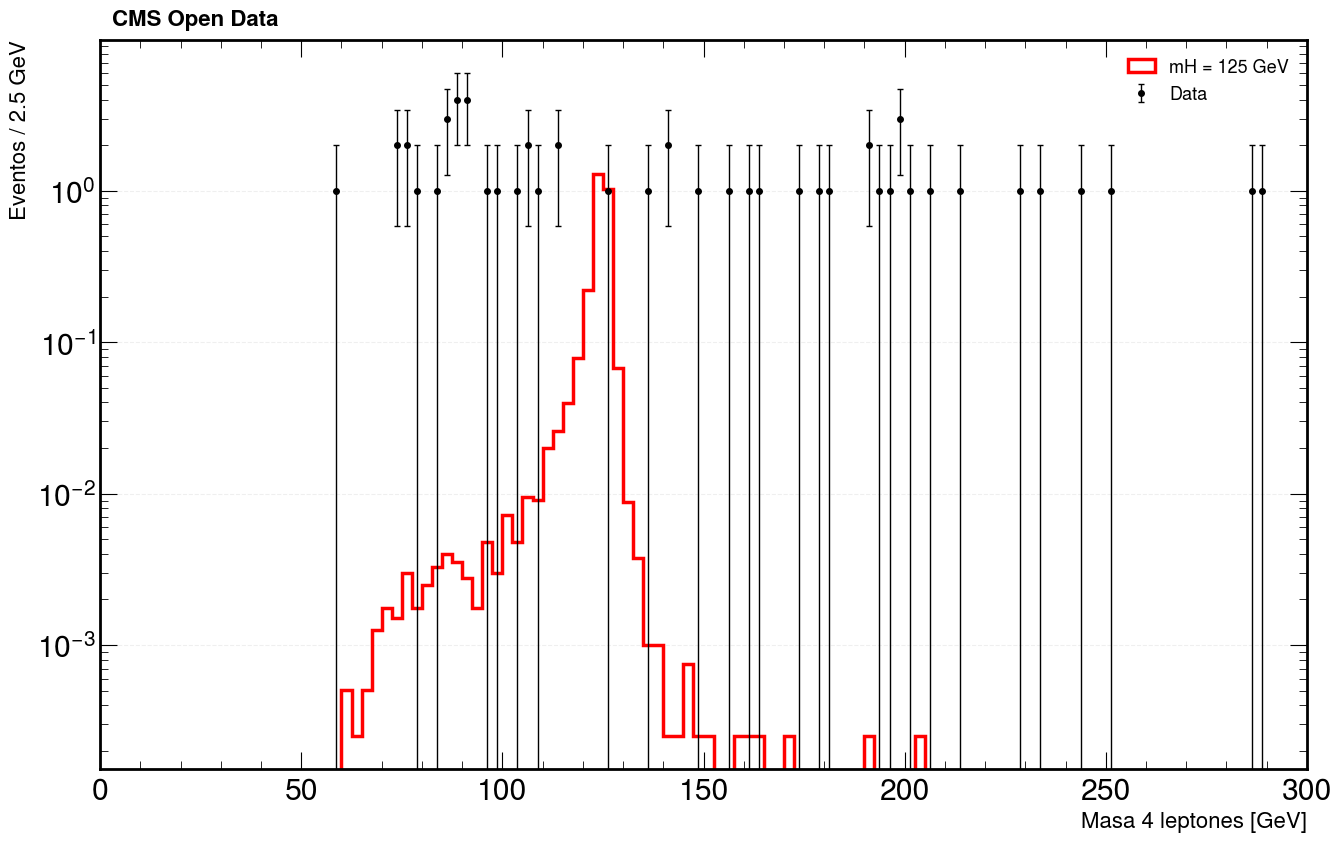

In [91]:
# Estilo CMS 
hep.style.use("CMS")

# Párametros Físicos
m_mu = 0.10566  # Masa del muón [GeV/c²]

# Reconstrucción del 4-vector del sistema de 4 muones
def calcular_masa(df):
    px = 0; py = 0; pz = 0; E = 0
    for i in range(1, 5):
        pxi = df[f"pt{i}"] * np.cos(df[f"phi{i}"])
        pyi = df[f"pt{i}"] * np.sin(df[f"phi{i}"])
        pzi = df[f"pt{i}"] * np.sinh(df[f"eta{i}"])
        Ei  = np.sqrt(pxi**2 + pyi**2 + pzi**2 + m_mu**2)
        px += pxi; py += pyi; pz += pzi; E += Ei
        
    # Protegemos el argumento contra negativos numéricos antes del return
    argumento_raiz = np.maximum(0, E**2 - (px**2 + py**2 + pz**2))
    return np.sqrt(argumento_raiz)

df_final["M"] = calcular_masa(df_final)

# Filtros para Higgs MC (usando df_4mu_higgs)
mask_pt_h  = (df_4mu_higgs["pt1"]>5)  & (df_4mu_higgs["pt2"]>5)  & (df_4mu_higgs["pt3"]>5)  & (df_4mu_higgs["pt4"]>5)
mask_eta_h = (df_4mu_higgs["eta1"].abs()<2.4) & (df_4mu_higgs["eta2"].abs()<2.4) & (df_4mu_higgs["eta3"].abs()<2.4) & (df_4mu_higgs["eta4"].abs()<2.4)
mask_iso_h = (df_4mu_higgs["iso1"]<0.40) & (df_4mu_higgs["iso2"]<0.40) & (df_4mu_higgs["iso3"]<0.40) & (df_4mu_higgs["iso4"]<0.40)
mask_dxy_h = (df_4mu_higgs["dxy1"].abs()<0.5) & (df_4mu_higgs["dxy2"].abs()<0.5) & (df_4mu_higgs["dxy3"].abs()<0.5) & (df_4mu_higgs["dxy4"].abs()<0.5)
mask_dz_h  = (df_4mu_higgs["dz1"].abs()<1.0)  & (df_4mu_higgs["dz2"].abs()<1.0)  & (df_4mu_higgs["dz3"].abs()<1.0)  & (df_4mu_higgs["dz4"].abs()<1.0)

df_higgs_f = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_dxy_h & mask_dz_h].copy()

for (i, j) in pares_todos:
    df_higgs_f[f"dR_{i}{j}"] = delta_R(df_higgs_f, i, j)

mask_dR_h = True
for (i, j) in pares_todos:
    mask_dR_h = mask_dR_h & (df_higgs_f[f"dR_{i}{j}"] > 0.02)

df_higgs_f = df_higgs_f[mask_dR_h].copy()

df_higgs_f = identificar_Z_onoff(df_higgs_f)

df_higgs_f = df_higgs_f[
    (df_higgs_f["mZ1"] > 40) & (df_higgs_f["mZ1"] < 120) &
    (df_higgs_f["mZ2"] > 12) & (df_higgs_f["mZ2"] < 120)
].copy()

df_higgs_f["M"] = calcular_masa(df_higgs_f)

df_data_f = df_final

print("Datos reales filtrados:", len(df_data_f))
print("Higgs filtrado:       ", len(df_higgs_f))

# Pesos oficiales del CERN  scale_higgs y scale_zz
lumi    = 11.58 * 1000
w_higgs = (0.0065 * lumi) / 299973.0

print(f"Peso Higgs: {w_higgs:.4f}")


# Gráfico de la Distribución de la masa invariante

mis_bins = np.arange(0, 300, 2.5)

plt.figure(figsize=(14, 9))

plt.hist(df_higgs_f["M"], bins=mis_bins,
         weights=np.full(len(df_higgs_f), w_higgs),
         label="mH = 125 GeV", color="red", histtype='step', linewidth=2.5)

counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
plt.errorbar(bin_centers, counts, yerr=np.sqrt(counts),
             fmt='o', color='black', markersize=4,
             capsize=2, elinewidth=1, linestyle='none', label='Data')

ax = plt.gca()
ax.text(0.01, 1.02, "CMS Open Data", transform=ax.transAxes,
        fontsize=16, fontweight='bold', fontstyle='normal', ha='left')
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 2.5 GeV", fontsize=16)
plt.xlim(0, 300)      # ahora se ve el espectro, incluido lo que estaba oculto
# sin ylim fijo, para no cortar picos altos:
plt.yscale("log")     # escala log, útil cuando hay picos muy dispares en altura

plt.legend(loc='upper right', frameon=False, fontsize=13)
plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()


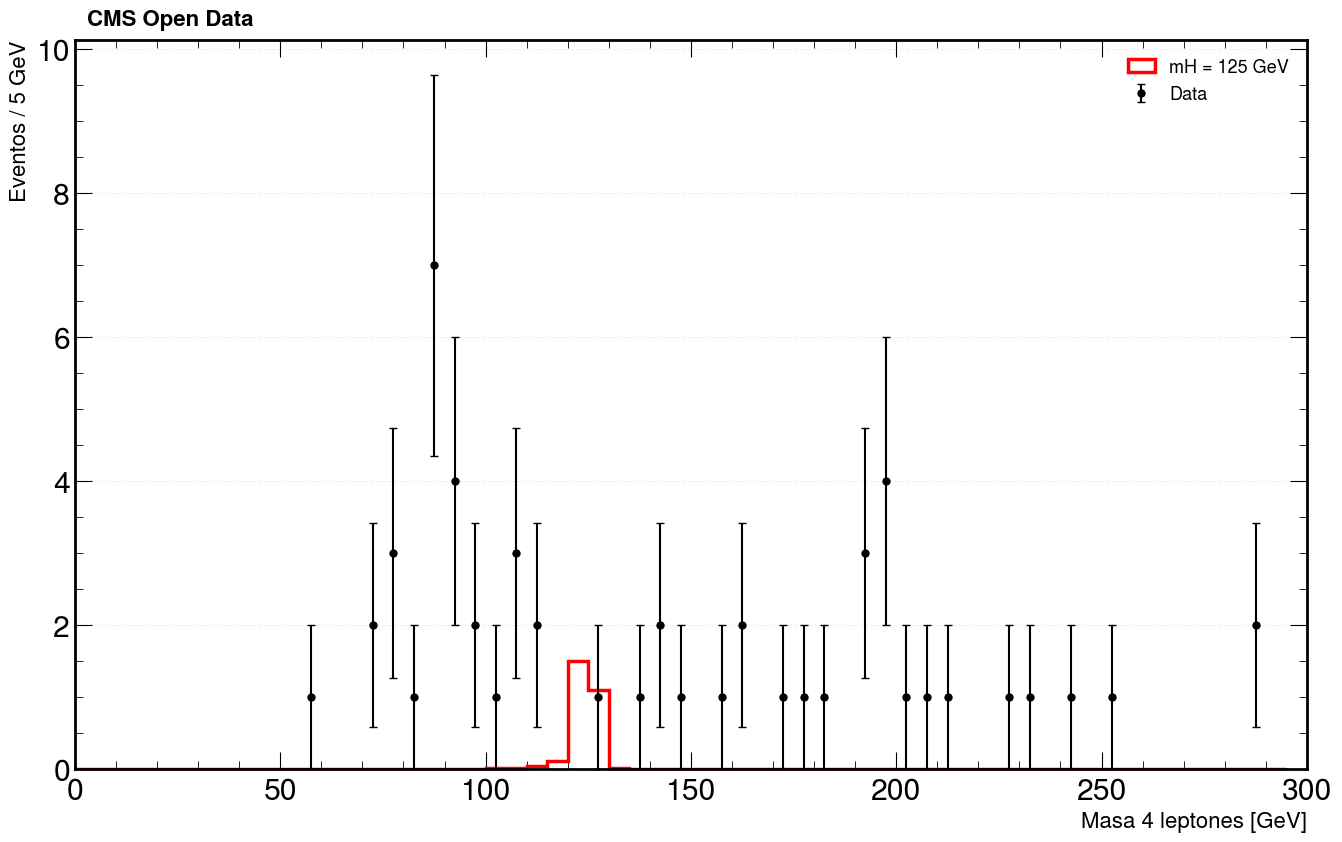

In [102]:
# Gráfico de la Distribución de la masa invariante (Versión limpia)

mis_bins = np.arange(0, 300, 5) # Cambiamos a 5 GeV por bin para tener mejor estadística por bin

plt.figure(figsize=(14, 9))

# Histograma del Higgs simulado
plt.hist(df_higgs_f["M"], bins=mis_bins,
         weights=np.full(len(df_higgs_f), w_higgs),
         label="mH = 125 GeV", color="red", histtype='step', linewidth=2.5)

# Procesar datos para no mostrar barras de error en los ceros
counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2

# Filtramos para graficar solo los bins que tienen al menos 1 evento
mask_no_zeros = counts > 0

plt.errorbar(bin_centers[mask_no_zeros], counts[mask_no_zeros], 
             yerr=np.sqrt(counts[mask_no_zeros]),
             fmt='o', color='black', markersize=5,
             capsize=3, elinewidth=1.5, linestyle='none', label='Data')

ax = plt.gca()
ax.text(0.01, 1.02, "CMS Open Data", transform=ax.transAxes,
        fontsize=16, fontweight='bold', fontstyle='normal', ha='left')
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 5 GeV", fontsize=16)
plt.xlim(0, 300)      
plt.ylim(bottom=0)

plt.legend(loc='upper right', frameon=False, fontsize=13)
plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

In [103]:
print("Masa máxima en df_data_f:", df_data_f["M"].max())
print(df_data_f.nlargest(10, "M")[["pt1","pt2","pt3","pt4","mZ1","mZ2","M"]])

Masa máxima en df_data_f: 742.1458
                pt1         pt2         pt3         pt4        mZ1        mZ2  \
1794499   39.527660   44.417023   57.386845   31.205700  90.104103  83.881195   
3282675   48.569305   23.082291  104.934151   53.701954  91.981255  93.386459   
2330420    8.631541   98.232346  302.673920  117.112061  87.875801  16.025614   
2688368  103.030708   38.486107   26.232498  104.638412  89.855537  94.146996   
1974094   77.994293   35.778572   29.906015   79.748543  90.549103  96.737724   
1402542   53.082214  145.748657   98.838593   17.150621  89.686562  96.251175   
1050146   53.029343   65.574028   15.358315   25.564159  97.707069  46.005188   
208262    90.864883   20.805326   27.710430   90.702911  93.602020  95.924805   
2133191   88.352409   24.341776   16.205063  116.455757  90.436615  34.021938   
491540    27.129280   22.576851   50.464939   82.017212  90.860069  88.971817   

                  M  
1794499  742.145813  
3282675  548.465393  
2330420

In [104]:
# ¿Cuántos eventos quedan solo con dxy/dz, antes de cualquier otra cosa?
mask_dxy_check = (df_4mu["dxy1"].abs()<0.5) & (df_4mu["dxy2"].abs()<0.5) & (df_4mu["dxy3"].abs()<0.5) & (df_4mu["dxy4"].abs()<0.5)
mask_dz_check  = (df_4mu["dz1"].abs()<1.0)  & (df_4mu["dz2"].abs()<1.0)  & (df_4mu["dz3"].abs()<1.0)  & (df_4mu["dz4"].abs()<1.0)
print("Solo dxy/dz (sobre df_4mu completo):", (mask_dxy_check & mask_dz_check).sum())

Solo dxy/dz (sobre df_4mu completo): 73180


In [105]:
print("df_4mu total:", len(df_4mu))
print("df_final (después del cutflow completo con dxy/dz):", len(df_final))

df_4mu total: 3340080
df_final (después del cutflow completo con dxy/dz): 59
